# Multimodal fusion results: late fusion vs cross-attention
Compare saved GBM experiments using clinical survival labels, genomic data, and WSI features. This notebook reads saved results and does not train models.

C-index measures survival ranking; accuracy measures survival-class prediction. Counts are matched records and may include repeated patient IDs. Saved files do not establish which architecture revision produced them, so interpret comparisons as results of the saved runs, not a controlled architecture-only experiment.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "result").is_dir():
    ROOT = ROOT.parent
DATASET = "normalized_zscore_gbm.csv"
MODELS = {"Late fusion": "multimodal_late_fusion", "Cross-attention": "multimodal_cross_attention"}
OUTPUT_DIR = ROOT / "result/comparisons/multimodal"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    path = OUTPUT_DIR / name
    plt.gcf().savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)

frames = []
for name, model in MODELS.items():
    path = ROOT / "result" / model / DATASET / "summary.csv"
    frame = pd.read_csv(path)
    frame = frame[pd.to_numeric(frame["fold"], errors="coerce").notna()].copy()
    frame["fold"] = frame["fold"].astype(int)
    frame["Model"] = name
    frames.append(frame)
fold_results = pd.concat(frames, ignore_index=True)
metrics = ["train_cindex", "final_val_cindex", "train_loss", "final_val_loss"]
display(fold_results[["Model", "fold"] + metrics])
comparison = fold_results.groupby("Model", sort=False)[metrics].agg(["mean", "std"])
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / "fusion_mean_std.csv")
fold_results.to_csv(OUTPUT_DIR / "fusion_fold_results.csv", index=False)


,Model,fold,train_cindex,final_val_cindex,train_loss,final_val_loss
0,Late fusion,0,0.868669,0.548352,0.000265,6.795483
1,Late fusion,1,0.870488,0.553286,0.000190,6.352129
2,Late fusion,2,0.864928,0.533062,0.000269,6.545807
3,Late fusion,3,0.874804,0.569182,0.000124,6.631268
4,Late fusion,4,0.879488,0.668944,0.000849,4.983170
5,Cross-attention,0,0.878920,0.527937,0.001399,6.265027
6,Cross-attention,1,0.881529,0.561279,0.000251,6.049242
7,Cross-attention,2,0.877237,0.549819,0.000929,6.137061
8,Cross-attention,3,0.865336,0.539832,0.000163,6.671752
9,Cross-attention,4,0.866131,0.655738,0.000475,5.124706


train_cindex         final_val_cindex         train_loss  \
                        mean     std             mean     std       mean   
Model                                                                      
Late fusion           0.8717  0.0056           0.5746  0.0543     0.0003   
Cross-attention       0.8738  0.0076           0.5669  0.0512     0.0006   

                        final_val_loss          
                    std           mean     std  
Model                                           
Late fusion      0.0003         6.2616  0.7323  
Cross-attention  0.0005         6.0496  0.5693

Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/fusion_training_validation_comparison.png


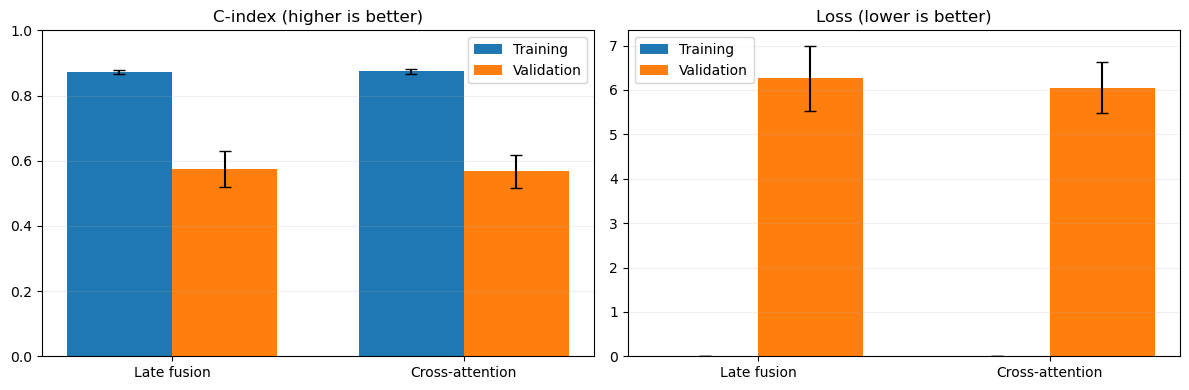

In [2]:
# Mean final training/validation metrics; error bars show variation across folds.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(MODELS))
for ax, columns, title in [
    (axes[0], ["train_cindex", "final_val_cindex"], "C-index (higher is better)"),
    (axes[1], ["train_loss", "final_val_loss"], "Loss (lower is better)"),
]:
    for offset, column, label in zip([-0.18, 0.18], columns, ["Training", "Validation"]):
        stats = fold_results.groupby("Model", sort=False)[column].agg(["mean", "std"])
        ax.bar(x + offset, stats["mean"], width=0.36, yerr=stats["std"].fillna(0), capsize=4, label=label)
    ax.set_xticks(x, list(MODELS))
    ax.set_title(title)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylim(0, 1)
fig.tight_layout()
save_figure("fusion_training_validation_comparison.png")
plt.show()


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/fusion_validation_by_fold.png


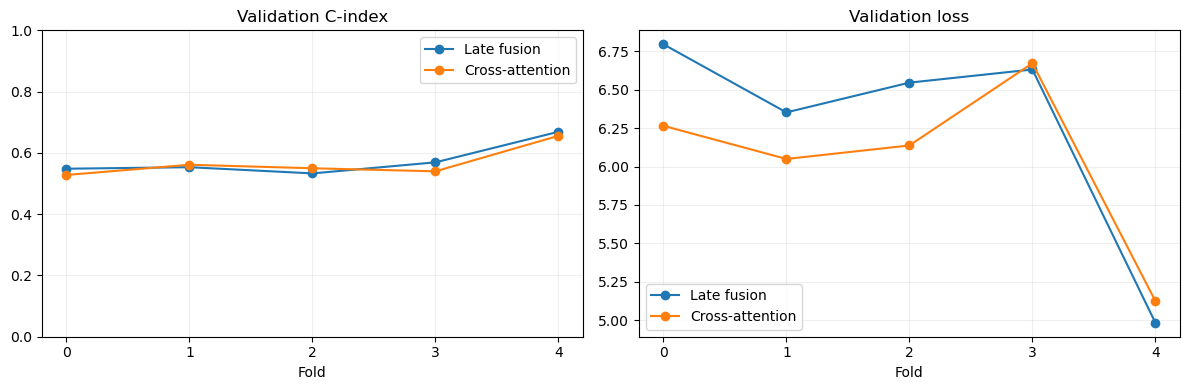

In [3]:
# Compare validation performance fold by fold.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in MODELS:
    values = fold_results[fold_results["Model"] == name].sort_values("fold")
    axes[0].plot(values["fold"], values["final_val_cindex"], marker="o", label=name)
    axes[1].plot(values["fold"], values["final_val_loss"], marker="o", label=name)
for ax, title in zip(axes, ["Validation C-index", "Validation loss"]):
    ax.set(title=title, xlabel="Fold")
    ax.set_xticks(sorted(fold_results["fold"].unique()))
    ax.legend()
    ax.grid(alpha=0.2)
axes[0].set_ylim(0, 1)
fig.tight_layout()
save_figure("fusion_validation_by_fold.png")
plt.show()


## One-fold validation predictions
Choose `FOLD` below. Every CSV row contributes once to its model's confusion matrix; no patient averaging or fold concatenation is performed. Duplicate patient records can affect these sample-level metrics.

,Model,Fold,Samples,Unique patients,Accuracy
0,Late fusion,0,59,59,0.322034
1,Cross-attention,0,59,59,0.406780


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/fusion_fold_0_confusion_matrices.png


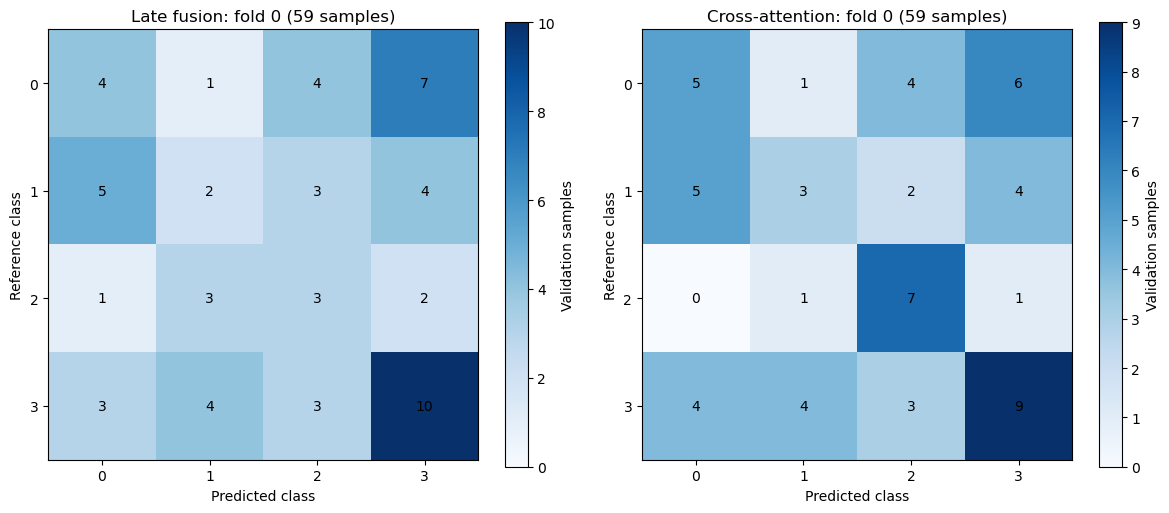

In [4]:
FOLD = 0
predictions = {}
rows = []
for name, model in MODELS.items():
    path = ROOT / "result" / f"split_{model}_{DATASET}_{FOLD}_predictions.csv"
    data = pd.read_csv(path)
    if data.empty:
        raise ValueError(f"No validation predictions in {path}")
    predictions[name] = data
    rows.append({"Model": name, "Fold": FOLD, "Samples": len(data),
                 "Unique patients": data["case_id"].nunique(),
                 "Accuracy": (data["label"] == data["prediction"]).mean()})
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, data) in zip(axes, predictions.items()):
    matrix = pd.crosstab(data["label"], data["prediction"]).reindex(index=range(4), columns=range(4), fill_value=0).to_numpy()
    assert matrix.sum() == len(data), "Unexpected class labels."
    heat = ax.imshow(matrix, cmap="Blues", vmin=0)
    for row in range(4):
        for col in range(4):
            ax.text(col, row, matrix[row, col], ha="center", va="center")
    ax.set(xticks=range(4), yticks=range(4), xlabel="Predicted class", ylabel="Reference class",
           title=f"{name}: fold {FOLD} ({len(data)} samples)")
    fig.colorbar(heat, ax=ax, label="Validation samples")
fig.tight_layout()
save_figure(f"fusion_fold_{FOLD}_confusion_matrices.png")
plt.show()


## Training curves
Only histories whose last training loss and C-index match the saved summary are shown. Validation is recorded at the end of training, so it appears as a final point rather than an invented epoch curve.

Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/fusion_fold_0_training_curves.png


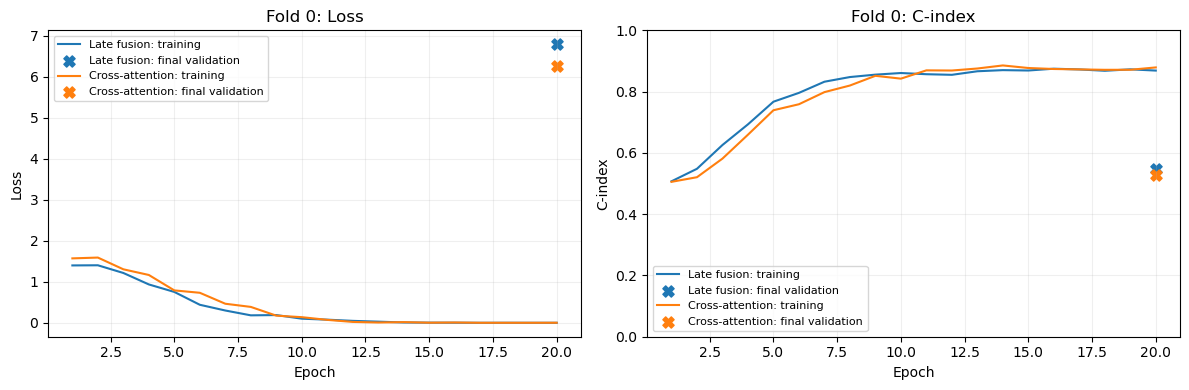

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
matched = 0
for name, model in MODELS.items():
    rows = fold_results[(fold_results["Model"] == name) & (fold_results["fold"] == FOLD)]
    path = ROOT / "result" / model / DATASET / f"training_history_fold_{FOLD}.csv"
    if rows.empty or not path.exists():
        print(f"No saved history for {name}, fold {FOLD}.")
        continue
    history = pd.read_csv(path)
    row = rows.iloc[0]
    if history.empty or not np.allclose(history.iloc[-1][["train_loss", "train_cindex"]].to_numpy(float),
                                       [row["train_loss"], row["train_cindex"]], rtol=1e-4, atol=1e-6):
        print(f"Skipping {name}: history does not match its summary.")
        continue
    matched += 1
    epochs = np.arange(1, len(history) + 1)
    for ax, train, val in [(axes[0], "train_loss", "final_val_loss"), (axes[1], "train_cindex", "final_val_cindex")]:
        line, = ax.plot(epochs, history[train], label=f"{name}: training")
        ax.scatter(epochs[-1], row[val], marker="X", s=65, color=line.get_color(), label=f"{name}: final validation")
if matched:
    for ax, title in zip(axes, ["Loss", "C-index"]):
        ax.set(title=f"Fold {FOLD}: {title}", xlabel="Epoch", ylabel=title)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    axes[1].set_ylim(0, 1)
    fig.tight_layout()
    save_figure(f"fusion_fold_{FOLD}_training_curves.png")
    plt.show()
else:
    plt.close(fig)
